<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/code/01RAD_Ex04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Exercise 04: Multiple Linear Regression through Linear Algebra

Lecture 4 introduced the **multiple linear regression** model (vícerozměrná lineární regrese) in matrix form,

$$\mathbf{Y} = \mathbf{X}\boldsymbol{\beta} + \mathbf{e}, \qquad \mathbf{e} \sim N_n(\mathbf{0}, \sigma^2 \mathbf{I}_n), \qquad (\ast\ast)$$

with the **model matrix** $\mathbf{X}$ of size $n \times (m+1)$ (matice modelu, regresní matice), and the **normal equations** (soustava normálních rovnic) $\mathbf{X}^T\mathbf{X}\boldsymbol{\beta} = \mathbf{X}^T\mathbf{y}$. The next lecture will derive the properties of the estimates $\widehat{\boldsymbol{\beta}}$ and $s_n^2$.

This exercise looks at the same model with the eyes of linear algebra, a point of view that the lectures use in the proofs but do not develop much further: least squares is an **orthogonal projection**, the fitted values do not depend on how we parametrise the columns of $\mathbf{X}$, and the way we *compute* $\widehat{\boldsymbol{\beta}}$ matters. Remark 3.1 mentioned the Cholesky, QR and singular value decompositions; here we implement all of them and see when they give different answers. R equivalents are mentioned in brackets.

## Learning goals
- Build the model matrix $\mathbf{X}$ from a formula (intercept, numerical variables, dummy variables, interactions, polynomial terms) and explain why the model is still *linear*.
- Interpret the normal equations as orthogonality of the residual vector to the columns of $\mathbf{X}$, and $\widehat{\mathbf{y}}$ as the orthogonal projection of $\mathbf{y}$ onto the column space of $\mathbf{X}$.
- Verify the properties of the projection matrices $\mathbf{H}$ and $\mathbf{M} = \mathbf{I}_n - \mathbf{H}$ (Remark 3.4), and connect $h_{ii}$ with the studentized residuals of Lecture 4.
- See that a multiple regression coefficient is a slope after removing the other regressors (Frisch–Waugh–Lovell), which explains why it differs from the simple regression slope.
- Recognise a rank-deficient $\mathbf{X}$ (Theorems 3.2 and 3.3), e.g. the dummy variable trap, and know what software does with it.
- Compute $\widehat{\boldsymbol{\beta}}$ by the normal equations, Cholesky, QR and SVD, relate the accuracy to the condition number, and check it against the certified NIST results for the Longley data.

Theorem and remark numbers refer to the lecture slides `lectures/01RAD_2024.pdf` (Chapter 3 starts on p. 65; Theorems 3.1–3.3 on pp. 66–70, Examples 3.1–3.2 on pp. 72–73, Remark 3.4 on p. 75).

## 1. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.linalg as sla
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import dmatrices

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.precision', 4)
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(2026)

In [2]:
url_mpg = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/mpg.csv'
try:
    mpg_raw = pd.read_csv(url_mpg)
except Exception:
    mpg_raw = sns.load_dataset('mpg')          # the same data set ships with seaborn
cars = mpg_raw.dropna().reset_index(drop=True)
print(f'{cars.shape[0]} cars')
cars.head()

392 cars


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## 2. Motivation: Example 3.1 from the lecture
Eight observations of two explanatory variables. Each of them alone explains little, $x_1$ almost nothing. Together they explain *everything*.

In [3]:
art = pd.DataFrame({'x1': [2, 3, 4, 1, 5, 6, 7, 8],
                    'x2': [1, 2, 5, 2, 6, 4, 3, 4],
                    'y':  [10, 17, 48, 27, 55, 26, 9, 16]})

rows = {}
for formula in ['y ~ x1', 'y ~ x2', 'y ~ x1 + x2']:
    fit = smf.ols(formula, data=art).fit()          # R: lm(y ~ x1 + x2, data = art)
    rows[formula] = {**{f'b_{k}': v for k, v in fit.params.items()}, 'R2': fit.rsquared}
pd.DataFrame(rows).T[['b_Intercept', 'b_x1', 'b_x2', 'R2']].round(4)

,b_Intercept,b_x1,b_x2,R2
y ~ x1,28.5714,-0.5714,NaN,0.0067
y ~ x2,-1.3396,NaN,8.1006,0.6356
y ~ x1 + x2,8.0000,-5.0000,12.0000,1.0000


The numbers agree with the slide: $\widehat{\beta}_1 = -0.57$ and $R^2 = 0.0067$ for $x_1$ alone, $R^2 = 0.636$ for $x_2$ alone, and the exact fit $y = 8 - 5x_1 + 12x_2$ with $R^2 = 1$ for both. (For an exact fit $s_n = 0$, so the $t$ statistics in `summary()` are meaningless; this is why we do not print it.)

The coefficient of $x_1$ changed from $-0.57$ to $-5$. In the multiple model $\beta_1$ is the effect of $x_1$ **when $x_2$ is held fixed**; in the simple model the effect of $x_1$ is mixed with the effect of $x_2$, which is correlated with $x_1$. The two pictures below show the marginal view (each variable alone) and the plane fitted in 3D.

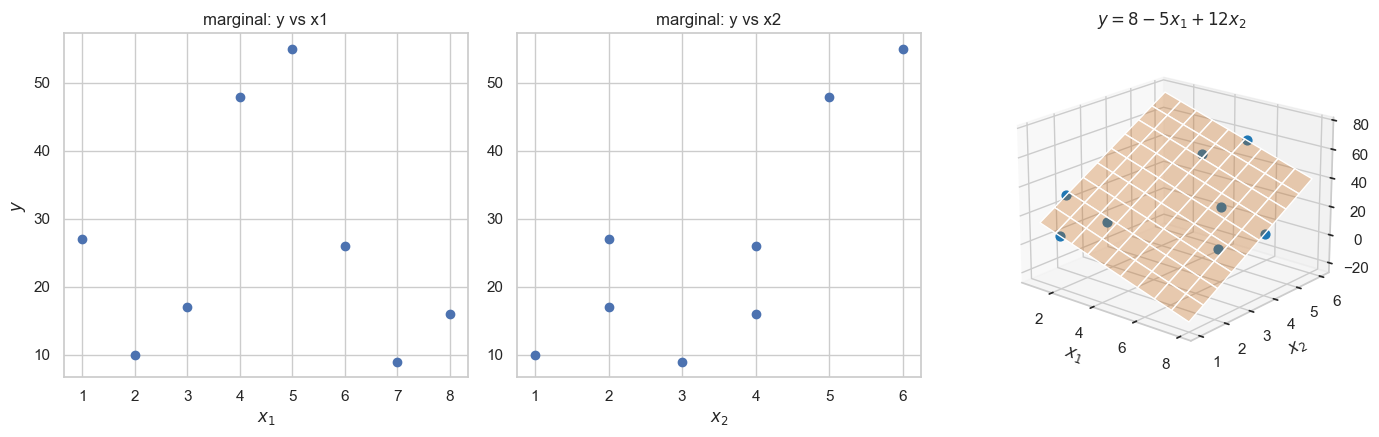

correlation of x1 and x2: 0.536


In [4]:
fig = plt.figure(figsize=(14, 4.5))
ax1 = fig.add_subplot(1, 3, 1)
ax1.scatter(art['x1'], art['y']); ax1.set_xlabel('$x_1$'); ax1.set_ylabel('$y$'); ax1.set_title('marginal: y vs x1')
ax2 = fig.add_subplot(1, 3, 2)
ax2.scatter(art['x2'], art['y']); ax2.set_xlabel('$x_2$'); ax2.set_title('marginal: y vs x2')
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
g1, g2 = np.meshgrid(np.linspace(1, 8, 10), np.linspace(1, 6, 10))
ax3.plot_surface(g1, g2, 8 - 5 * g1 + 12 * g2, alpha=0.3, color='tab:orange')
ax3.scatter(art['x1'], art['y'] * 0 + art['x2'], art['y'], color='tab:blue', s=40, depthshade=False)
ax3.set_xlabel('$x_1$'); ax3.set_ylabel('$x_2$'); ax3.set_zlabel('$y$'); ax3.set_title('$y = 8 - 5x_1 + 12x_2$')
ax3.view_init(elev=20, azim=-50)
plt.tight_layout()
plt.show()
print(f'correlation of x1 and x2: {art["x1"].corr(art["x2"]):.3f}')

Keep this example in mind; Section 6 explains the change of the coefficient exactly.

## 3. The model matrix $\mathbf{X}$
In $(\ast\ast)$ row $i$ of $\mathbf{X}$ is $\mathbf{x}_i^T = (1, x_{i1}, \dots, x_{im})$. The columns do not have to be the raw measured variables: any known function of them can be a column. The model is **linear in the parameters** $\boldsymbol{\beta}$, not necessarily in the variables. A formula such as

`mpg ~ weight + horsepower + origin + weight:origin + I(weight**2)`

is translated by `patsy` (used by `statsmodels.formula`) into a numerical matrix (R: `model.matrix(mod)`):

In [5]:
y_df, X_df = dmatrices('mpg ~ weight + horsepower + origin + weight:origin + I(weight**2)',
                       data=cars, return_type='dataframe')
print('shape of X:', X_df.shape)
X_df.head()

shape of X: (392, 8)


,Intercept,origin[T.japan],origin[T.usa],weight,weight:origin[T.japan],weight:origin[T.usa],horsepower,I(weight ** 2)
0,1.0,0.0,1.0,3504.0,0.0,3504.0,130.0,1.2278e+07
1,1.0,0.0,1.0,3693.0,0.0,3693.0,165.0,1.3638e+07
2,1.0,0.0,1.0,3436.0,0.0,3436.0,150.0,1.1806e+07
3,1.0,0.0,1.0,3433.0,0.0,3433.0,150.0,1.1785e+07
4,1.0,0.0,1.0,3449.0,0.0,3449.0,140.0,1.1896e+07


In [6]:
cars[['weight', 'horsepower', 'origin']].head()

,weight,horsepower,origin
0,3504,130.0,usa
1,3693,165.0,usa
2,3436,150.0,usa
3,3433,150.0,usa
4,3449,140.0,usa


- `Intercept` is the column of ones.
- The factor `origin` with three levels (europe, japan, usa) gives **two dummy variables** (indikátorové proměnné) `origin[T.japan]` and `origin[T.usa]`; the first level, `europe`, is the **reference level** (referenční úroveň), represented by zeros in both columns. Section 7 shows why there are not three.
- `weight:origin` multiplies `weight` by each dummy: a different slope for each origin.
- `I(weight ** 2)` is a polynomial term; the curve in `weight` is still a model linear in $\boldsymbol{\beta}$.

The interpretation of dummy variables and interactions (Example 3.2, birth weight) will be the topic of the next exercise. Here we only need $\mathbf{X}$ as a matrix. For the rest of the exercise we use the simpler model `mpg ~ weight + horsepower`.

In [7]:
y_df, X_df = dmatrices('mpg ~ weight + horsepower', data=cars, return_type='dataframe')
X = X_df.to_numpy()
y = y_df.to_numpy().ravel()
n, p = X.shape                    # p = m + 1
print(f'n = {n}, p = m + 1 = {p}')

model = sm.OLS(y, X).fit()        # R: mod <- lm(mpg ~ weight + horsepower, data = cars)
print(model.params)

n = 392, p = m + 1 = 3
[45.6402 -0.0058 -0.0473]


## 4. Normal equations and the geometry of least squares
The least squares estimate minimises $g(\boldsymbol{\beta}) = (\mathbf{y} - \mathbf{X}\boldsymbol{\beta})^T(\mathbf{y} - \mathbf{X}\boldsymbol{\beta}) = \|\mathbf{y} - \mathbf{X}\boldsymbol{\beta}\|^2$. Theorem 3.1 states that $\widehat{\boldsymbol{\beta}}$ solves the normal equations

$$\mathbf{X}^T\mathbf{X}\widehat{\boldsymbol{\beta}} = \mathbf{X}^T\mathbf{y} \quad\Longleftrightarrow\quad \mathbf{X}^T(\mathbf{y} - \mathbf{X}\widehat{\boldsymbol{\beta}}) = \mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}.$$

Read the second form column by column: the residual vector $\widehat{\mathbf{e}}$ is **orthogonal to every column of $\mathbf{X}$**. For the column of ones this is $\sum_i \widehat{e}_i = 0$, for a column $\mathbf{x}_j$ it is $\sum_i x_{ij}\widehat{e}_i = 0$; these are the equations (N1) and (N2) of Exercise 03, now for any number of columns.

Geometrically, all vectors $\mathbf{X}\boldsymbol{\beta}$ form the **column space** $\mathcal{M}(\mathbf{X}) \subset \mathbb{R}^n$ (sloupcový prostor, lineární obal sloupců $\mathbf{X}$), a subspace of dimension $h(\mathbf{X}) = m+1$. The point of $\mathcal{M}(\mathbf{X})$ nearest to $\mathbf{y}$ is the **orthogonal projection** (ortogonální projekce) $\widehat{\mathbf{y}} = \mathbf{X}\widehat{\boldsymbol{\beta}}$, and the residual $\widehat{\mathbf{e}} = \mathbf{y} - \widehat{\mathbf{y}}$ is perpendicular to the subspace.

In [8]:
beta_hat = np.linalg.solve(X.T @ X, X.T @ y)
y_hat = X @ beta_hat
e_hat = y - y_hat
print('beta_hat              :', beta_hat)
print('statsmodels           :', model.params)
print('X^T e_hat             :', np.array2string(X.T @ e_hat, formatter={'float_kind': '{:.2e}'.format}))
print('relative to |X^T y|   :', np.array2string(np.abs(X.T @ e_hat) / np.abs(X.T @ y), formatter={'float_kind': '{:.2e}'.format}))
print(f'y_hat^T e_hat / |y_hat|^2 = {(y_hat @ e_hat) / (y_hat @ y_hat):.2e}')

beta_hat              : [45.6402 -0.0058 -0.0473]
statsmodels           : [45.6402 -0.0058 -0.0473]
X^T e_hat             : [1.17e-13 7.55e-09 2.50e-11]
relative to |X^T y|   : [1.28e-17 3.00e-16 2.88e-17]
y_hat^T e_hat / |y_hat|^2 = -1.56e-16


The products are not exactly zero but zero up to rounding errors (relative size about $10^{-16}$, the machine precision); keep that in mind for Section 8.

A picture is possible only for $n = 3$. Take three observations $x = (0, 1, 2)$, $y = (0, 3, 1)$ and the simple regression with intercept. The two columns $\mathbf{1} = (1,1,1)^T$ and $\mathbf{x} = (0,1,2)^T$ span a plane in $\mathbb{R}^3$; $\widehat{\mathbf{y}}$ is the foot of the perpendicular from $\mathbf{y}$ to that plane.

beta_hat = [0.8333 0.5   ], y_hat = [0.8333 1.3333 1.8333], e_hat = [-0.8333  1.6667 -0.8333], X^T e_hat = [-0. -0.]


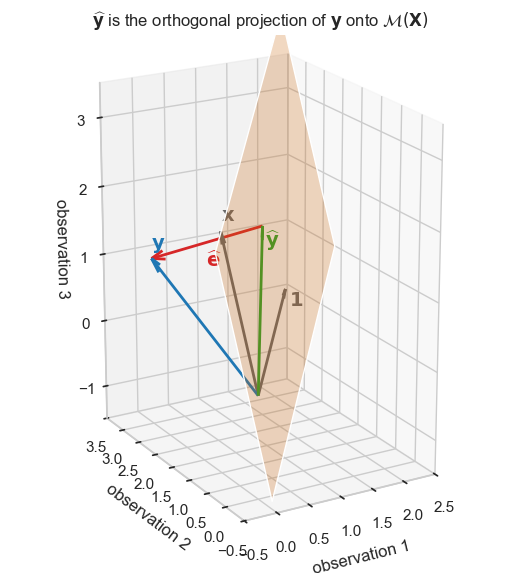

In [9]:
X3 = np.array([[1., 0.], [1., 1.], [1., 2.]])
y3 = np.array([0., 3., 1.])
b3 = np.linalg.solve(X3.T @ X3, X3.T @ y3)
yh3 = X3 @ b3
eh3 = y3 - yh3
print(f'beta_hat = {b3}, y_hat = {yh3}, e_hat = {eh3}, X^T e_hat = {X3.T @ eh3}')

fig = plt.figure(figsize=(7, 6.5))
ax = fig.add_subplot(projection='3d')
s, t = np.meshgrid(np.linspace(-0.2, 2.2, 2), np.linspace(-0.5, 1.0, 2))
plane = s[..., None] * X3[:, 0] + t[..., None] * X3[:, 1]           # points s*1 + t*x
ax.plot_surface(plane[..., 0], plane[..., 1], plane[..., 2], alpha=0.25, color='tab:orange')
O = np.zeros(3)
for vec, col, lab, off in [(X3[:, 0], 'dimgray', r'$\mathbf{1}$', (0.05, 0, -0.25)),
                           (X3[:, 1], 'dimgray', r'$\mathbf{x}$', (0, 0, 0.15)),
                           (y3, 'tab:blue', r'$\mathbf{y}$', (0, 0, 0.15)),
                           (yh3, 'tab:green', r'$\widehat{\mathbf{y}}$', (0.1, 0.1, -0.35))]:
    ax.quiver(*O, *vec, color=col, arrow_length_ratio=0.08, lw=2)
    ax.text(*(vec + np.array(off)), lab, color=col, fontsize=14)
ax.quiver(*yh3, *eh3, color='tab:red', arrow_length_ratio=0.12, lw=2)
ax.text(*(yh3 + eh3 / 2 + np.array([0, 0, -0.35])), r'$\widehat{\mathbf{e}}$', color='tab:red', fontsize=14)
ax.set_xlim(-0.5, 2.5); ax.set_ylim(-0.5, 3.5); ax.set_zlim(-1.5, 3.5)
ax.set_box_aspect((3, 4, 5))
ax.set_xlabel('observation 1'); ax.set_ylabel('observation 2'); ax.set_zlabel('observation 3')
ax.view_init(elev=20, azim=-120)
ax.set_title(r'$\widehat{\mathbf{y}}$ is the orthogonal projection of $\mathbf{y}$ onto $\mathcal{M}(\mathbf{X})$')
plt.show()

Note the axes: in this picture each **axis is an observation**, and each data vector ($\mathbf{y}$, $\mathbf{x}$, $\mathbf{1}$) is one point of $\mathbb{R}^n$. This is the opposite of the usual scatter plot, where each observation is a point. Both pictures are useful: the scatter plot for data analysis, the observation space for theory.

**Pythagoras.** Since $\widehat{\mathbf{y}} \perp \widehat{\mathbf{e}}$,
$$\|\mathbf{y}\|^2 = \|\widehat{\mathbf{y}}\|^2 + \|\widehat{\mathbf{e}}\|^2 .$$
With an intercept, $\mathbf{1} \in \mathcal{M}(\mathbf{X})$, and the same holds after subtracting $\overline{y}\,\mathbf{1}$ from both $\mathbf{y}$ and $\widehat{\mathbf{y}}$: this is exactly $\mathrm{SST} = \mathrm{SSR} + \mathrm{SSE}$ from Exercise 03, now for any number of regressors. The right triangle also gives a new reading of $R^2$: it is $\cos^2\theta$, where $\theta$ is the angle between the centred vectors $\mathbf{y} - \overline{y}\mathbf{1}$ and $\widehat{\mathbf{y}} - \overline{y}\mathbf{1}$, i.e. the squared correlation of $y_i$ and $\widehat{y}_i$ (the **multiple correlation coefficient**, koeficient mnohonásobné korelace).

In [10]:
y_c, yh_c = y - y.mean(), y_hat - y.mean()
SST, SSR, SSE = y_c @ y_c, yh_c @ yh_c, e_hat @ e_hat
cos_theta = (y_c @ yh_c) / np.sqrt(SST * SSR)
print(f'|y|^2 = {y @ y:.2f},  |y_hat|^2 + |e_hat|^2 = {y_hat @ y_hat + e_hat @ e_hat:.2f}')
print(f'SST = {SST:.2f},  SSR + SSE = {SSR + SSE:.2f}')
print(f'R^2 = SSR/SST = {SSR / SST:.4f},  cos^2(theta) = {cos_theta ** 2:.4f},  '
      f'corr(y, y_hat)^2 = {np.corrcoef(y, y_hat)[0, 1] ** 2:.4f},  statsmodels: {model.rsquared:.4f}')

|y|^2 = 239305.74,  |y_hat|^2 + |e_hat|^2 = 239305.74
SST = 23818.99,  SSR + SSE = 23818.99
R^2 = SSR/SST = 0.7064,  cos^2(theta) = 0.7064,  corr(y, y_hat)^2 = 0.7064,  statsmodels: 0.7064


**Exercise on the board.**
1. Write $g(\boldsymbol{\beta}) = \mathbf{y}^T\mathbf{y} - 2\boldsymbol{\beta}^T\mathbf{X}^T\mathbf{y} + \boldsymbol{\beta}^T\mathbf{X}^T\mathbf{X}\boldsymbol{\beta}$, compute the gradient $\partial g/\partial \boldsymbol{\beta}$ and derive the normal equations.
2. Let $\widehat{\boldsymbol{\beta}}$ be *any* solution of the normal equations. Show that for every $\boldsymbol{\beta} \in \mathbb{R}^{m+1}$
$$g(\boldsymbol{\beta}) = g(\widehat{\boldsymbol{\beta}}) + \|\mathbf{X}(\widehat{\boldsymbol{\beta}} - \boldsymbol{\beta})\|^2 ,$$
and conclude that every solution of the normal equations minimises $g$, without computing any second derivative.
3. From 2. show that two solutions $\widehat{\boldsymbol{\beta}}$, $\widetilde{\boldsymbol{\beta}}$ of the normal equations always give the same fitted values $\mathbf{X}\widehat{\boldsymbol{\beta}} = \mathbf{X}\widetilde{\boldsymbol{\beta}}$, even when they differ.

<!--
Solution.
1. d/dbeta (y^T y) = 0, d/dbeta (beta^T X^T y) = X^T y, d/dbeta (beta^T A beta) = 2 A beta for symmetric A = X^T X.
   Gradient: -2 X^T y + 2 X^T X beta = 0, i.e. X^T X beta = X^T y.
2. y - X beta = (y - X bhat) + X (bhat - beta). Squared norm:
   g(beta) = g(bhat) + |X (bhat - beta)|^2 + 2 (bhat - beta)^T X^T (y - X bhat),
   and the last term is zero because X^T (y - X bhat) = 0 (normal equations).
   Hence g(beta) >= g(bhat) for all beta: bhat is a minimum.
3. Both are minima, so g(btilde) = g(bhat). By 2. |X (bhat - btilde)|^2 = 0, hence X bhat = X btilde.
   This is the argument of the proof of Theorem 3.1 in the lecture notes.
-->

## 5. The projection matrices $\mathbf{H}$ and $\mathbf{M}$
If $h(\mathbf{X}) = m+1$, then $\widehat{\mathbf{y}} = \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y} = \mathbf{H}\mathbf{y}$ with the **hat matrix** (projekční matice, „hat“ matice)

$$\mathbf{H} = \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T, \qquad \mathbf{M} = \mathbf{I}_n - \mathbf{H}, \qquad \widehat{\mathbf{e}} = \mathbf{M}\mathbf{y}.$$

$\mathbf{H}$ projects onto $\mathcal{M}(\mathbf{X})$, $\mathbf{M}$ onto its orthogonal complement. Remark 3.4 lists their properties; we check them numerically for `mpg ~ weight + horsepower` ($n = 392$, so $\mathbf{H}$ has $392^2 \approx 150\,000$ entries).

In [11]:
H = X @ np.linalg.inv(X.T @ X) @ X.T
M = np.eye(n) - H

checks = {
    'H symmetric        max|H^T - H|': np.abs(H.T - H).max(),
    'H idempotent       max|H^2 - H|': np.abs(H @ H - H).max(),
    'M idempotent       max|M^2 - M|': np.abs(M @ M - M).max(),
    'HX = X             max|HX - X| / max|X|': np.abs(H @ X - X).max() / np.abs(X).max(),
    'HM = 0             max|HM|': np.abs(H @ M).max(),
    'Hy = y_hat         max|Hy - y_hat|': np.abs(H @ y - y_hat).max(),
    'My = e_hat         max|My - e_hat|': np.abs(M @ y - e_hat).max(),
}
for k, v in checks.items():
    print(f'{k:40s} {v:.2e}')
print(f'tr(H) = {np.trace(H):.6f},  m + 1 = {p};   tr(M) = {np.trace(M):.6f},  n - m - 1 = {n - p}')

H symmetric        max|H^T - H|          1.35e-16
H idempotent       max|H^2 - H|          2.22e-16
M idempotent       max|M^2 - M|          7.77e-16
HX = X             max|HX - X| / max|X|  1.04e-14
HM = 0             max|HM|               2.43e-16
Hy = y_hat         max|Hy - y_hat|       4.65e-13
My = e_hat         max|My - e_hat|       4.69e-13
tr(H) = 3.000000,  m + 1 = 3;   tr(M) = 389.000000,  n - m - 1 = 389


In [12]:
eig_H = np.linalg.eigvalsh(H)
print('eigenvalues of H rounded to 8 decimals and counted:')
print(pd.Series(np.round(eig_H, 8)).value_counts().sort_index())

eigenvalues of H rounded to 8 decimals and counted:
-0.0    389
 1.0      3
Name: count, dtype: int64


A symmetric idempotent matrix has eigenvalues $0$ and $1$ only ($\mathbf{H}\mathbf{v} = \lambda\mathbf{v}$ implies $\lambda\mathbf{v} = \mathbf{H}^2\mathbf{v} = \lambda^2\mathbf{v}$); the number of ones is the rank $m+1$ and equals the trace. The matrix $\mathbf{H}$ is $n \times n$ but has only $m+1$ "directions".

**$\mathbf{H}$ depends only on the column space.** If we replace $\mathbf{X}$ by $\mathbf{X}\mathbf{A}$ with a regular $(m+1)\times(m+1)$ matrix $\mathbf{A}$, then $\mathcal{M}(\mathbf{X}\mathbf{A}) = \mathcal{M}(\mathbf{X})$ and

$$\mathbf{X}\mathbf{A}\,\big(\mathbf{A}^T\mathbf{X}^T\mathbf{X}\mathbf{A}\big)^{-1}\mathbf{A}^T\mathbf{X}^T = \mathbf{H}.$$

Changing units, centring a variable, or replacing two regressors by their sum and difference are all of this form. The coefficients change, the fitted values, residuals, $s_n^2$ and $R^2$ do not. We try weight in kilograms and centred, horsepower in kW:

In [13]:
cars['weight_kg_c'] = 0.4536 * cars['weight'] - (0.4536 * cars['weight']).mean()
cars['kw'] = 0.7457 * cars['horsepower']
m_orig = smf.ols('mpg ~ weight + horsepower', data=cars).fit()
m_new = smf.ols('mpg ~ weight_kg_c + kw', data=cars).fit()

display(pd.DataFrame({'original': m_orig.params.values, 'kg centred, kW': m_new.params.values},
                     index=['Intercept', 'weight', 'horsepower']))
print(f'max |difference of fitted values| = {np.abs(m_orig.fittedvalues - m_new.fittedvalues).max():.2e}')
print(f's_n: {np.sqrt(m_orig.scale):.6f} vs {np.sqrt(m_new.scale):.6f},  R^2: {m_orig.rsquared:.6f} vs {m_new.rsquared:.6f}')
print(f'intercept of the centred model = fitted mpg of a car of average weight with 0 kW: {m_new.params.iloc[0]:.3f}')

,original,"kg centred, kW"
Intercept,45.6402,28.3876
weight,-0.0058,-0.0128
horsepower,-0.0473,-0.0634


max |difference of fitted values| = 1.39e-13
s_n: 4.240169 vs 4.240169,  R^2: 0.706375 vs 0.706375
intercept of the centred model = fitted mpg of a car of average weight with 0 kW: 28.388


**Link to Lecture 4: leverage and studentized residuals.** The diagonal elements $h_{ii}$ of $\mathbf{H}$ are the **leverages** (potenciály, diagonální prvky projekční matice). For simple regression

$$h_{ii} = \frac{1}{n} + \frac{(x_i - \overline{x})^2}{S_{xx}},$$

which is exactly the expression in the denominator of the studentized residuals of Lecture 4,
$\widehat{r}_i = \widehat{e}_i \big/ \big(s_n\sqrt{1 - h_{ii}}\big)$. The matrix formula works for any number of regressors.

In [14]:
# simple regression mpg ~ weight: h_ii from the matrix and from the Lecture 4 formula
x = cars['weight'].to_numpy(dtype=float)
X1 = np.column_stack([np.ones(n), x])
h_matrix = np.einsum('ij,ji->i', X1, np.linalg.solve(X1.T @ X1, X1.T))    # diag(H) without building H
h_formula = 1 / n + (x - x.mean()) ** 2 / np.sum((x - x.mean()) ** 2)
print(f'max |h_ii(matrix) - h_ii(formula)| = {np.abs(h_matrix - h_formula).max():.2e}')

# multiple regression: studentized residuals by hand and from statsmodels
h = np.diag(H)
s_n = np.sqrt(e_hat @ e_hat / (n - p))
r_hand = e_hat / (s_n * np.sqrt(1 - h))
r_sm = model.get_influence().resid_studentized_internal
print(f'max |r_i(hand) - r_i(statsmodels)| = {np.abs(r_hand - r_sm).max():.2e}')
print(f'mean leverage = {h.mean():.4f} = (m+1)/n = {p / n:.4f}')

max |h_ii(matrix) - h_ii(formula)| = 1.39e-17
max |r_i(hand) - r_i(statsmodels)| = 3.90e-14
mean leverage = 0.0077 = (m+1)/n = 0.0077


,name,mpg,weight,horsepower,h_ii
13,buick estate wagon (sw),14.0,3086,225.0,0.0950
115,pontiac grand prix,16.0,4278,230.0,0.0466
8,pontiac catalina,14.0,4425,225.0,0.0378
6,chevrolet impala,14.0,4354,220.0,0.0352
7,plymouth fury iii,14.0,4312,215.0,0.0321


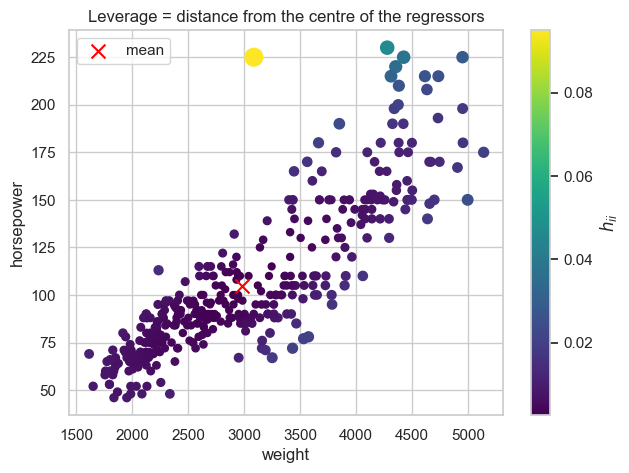

In [15]:
top = np.argsort(h)[::-1][:5]
display(cars.loc[top, ['name', 'mpg', 'weight', 'horsepower']].assign(h_ii=h[top]))

plt.figure(figsize=(7, 5))
sc = plt.scatter(cars['weight'], cars['horsepower'], c=h, cmap='viridis', s=20 + 1500 * h)
plt.colorbar(sc, label='$h_{ii}$')
plt.scatter(cars['weight'].mean(), cars['horsepower'].mean(), marker='x', color='red', s=100, label='mean')
plt.xlabel('weight'); plt.ylabel('horsepower'); plt.legend()
plt.title('Leverage = distance from the centre of the regressors')
plt.show()

Leverage depends only on $\mathbf{X}$, not on $\mathbf{y}$: the cars with the largest $h_{ii}$ are those far from the centre of the cloud of regressors. Here these are the most powerful cars, and the clear leader is the Buick estate wagon with 225 hp at only about 3100 lb, a combination no other car in the data has. What large leverage means for the fit (influential observations, Cook's distance) will come with the regression diagnostics later in the course.

**Exercise on the board.** Assume $h(\mathbf{X}) = m+1$.
1. Show $\mathbf{H}^T = \mathbf{H}$, $\mathbf{H}^2 = \mathbf{H}$, $\mathbf{H}\mathbf{X} = \mathbf{X}$ and $\mathbf{M}\mathbf{X} = \mathbf{0}$.
2. Using $\mathrm{tr}(\mathbf{A}\mathbf{B}) = \mathrm{tr}(\mathbf{B}\mathbf{A})$, show $\mathrm{tr}(\mathbf{H}) = m+1$ and $\mathrm{tr}(\mathbf{M}) = n - m - 1$. Where have you seen $n - m - 1$ before?
3. Show $\widehat{\mathbf{e}} = \mathbf{M}\mathbf{y} = \mathbf{M}\mathbf{e}$: the residuals depend on the unknown errors only, not on $\boldsymbol{\beta}$.
4. Show that $0 \le h_{ii} \le 1$. (Hint: $h_{ii} = (\mathbf{H}^2)_{ii} = \sum_j h_{ij}^2$.)

<!--
Solution.
1. H^T = X ((X^T X)^{-1})^T X^T = X (X^T X)^{-1} X^T = H, since X^T X is symmetric.
   H^2 = X (X^T X)^{-1} X^T X (X^T X)^{-1} X^T = X (X^T X)^{-1} X^T = H.
   H X = X (X^T X)^{-1} X^T X = X, M X = X - H X = 0.
2. tr(H) = tr(X (X^T X)^{-1} X^T) = tr((X^T X)^{-1} X^T X) = tr(I_{m+1}) = m + 1; tr(M) = tr(I_n) - tr(H) = n - m - 1.
   n - m - 1 is the denominator of s_n^2 = SSE/(n - m - 1) (for simple regression n - 2): the residual vector lives in an
   (n - m - 1)-dimensional subspace, its degrees of freedom.
3. M y = M (X beta + e) = M X beta + M e = M e.
4. h_ii = sum_j h_ij h_ji = sum_j h_ij^2 = h_ii^2 + sum_{j != i} h_ij^2 >= h_ii^2, hence h_ii (1 - h_ii) >= 0, so 0 <= h_ii <= 1.
   (With an intercept even h_ii >= 1/n.)
-->

## 6. What does a multiple regression coefficient mean? (Frisch–Waugh–Lovell)
Split $\mathbf{X} = (\mathbf{X}_{-j}, \mathbf{x}_j)$ into the column $\mathbf{x}_j$ and all other columns $\mathbf{X}_{-j}$, and let $\mathbf{M}_{-j} = \mathbf{I}_n - \mathbf{H}_{-j}$ be the residual-maker of the model with $\mathbf{X}_{-j}$ only. Then

$$\widehat{\beta}_j = \frac{\langle \mathbf{M}_{-j}\mathbf{x}_j\,;\, \mathbf{M}_{-j}\mathbf{y}\rangle}{\|\mathbf{M}_{-j}\mathbf{x}_j\|^2},$$

the slope of a simple regression through the origin of "$\mathbf{y}$ cleaned of the other regressors" on "$\mathbf{x}_j$ cleaned of the other regressors". In words: $\widehat{\beta}_j$ uses only the part of $x_j$ that the other regressors cannot explain. This is the **Frisch–Waugh–Lovell theorem**. It is not in the lectures; we only verify it here, and Exercise 07 will turn it into the **added-variable plot** (partial regression plot), one of the main diagnostic tools.

In [16]:
def residual_maker(Z):
    """Residuals of the projection onto the columns of Z, as a function."""
    Q_z, _ = np.linalg.qr(Z)
    return lambda v: v - Q_z @ (Q_z.T @ v)

# mpg ~ weight + horsepower: the coefficient of weight
M_other = residual_maker(X[:, [0, 2]])           # intercept and horsepower
x_tilde, y_tilde = M_other(X[:, 1]), M_other(y)
print(f'FWL slope for weight      : {(x_tilde @ y_tilde) / (x_tilde @ x_tilde):.6f}')
print(f'multiple regression       : {model.params[1]:.6f}')
print(f'simple regression on weight: {np.polyfit(X[:, 1], y, 1)[0]:.6f}')

# Example 3.1: the coefficient of x1
Xa = np.column_stack([np.ones(8), art['x1'], art['x2']])
ya = art['y'].to_numpy(dtype=float)
M_a = residual_maker(Xa[:, [0, 2]])
x1_tilde, ya_tilde = M_a(Xa[:, 1]), M_a(ya)
print(f'\nExample 3.1, FWL slope for x1: {(x1_tilde @ ya_tilde) / (x1_tilde @ x1_tilde):.4f}')

FWL slope for weight      : -0.005794
multiple regression       : -0.005794
simple regression on weight: -0.007647

Example 3.1, FWL slope for x1: -5.0000


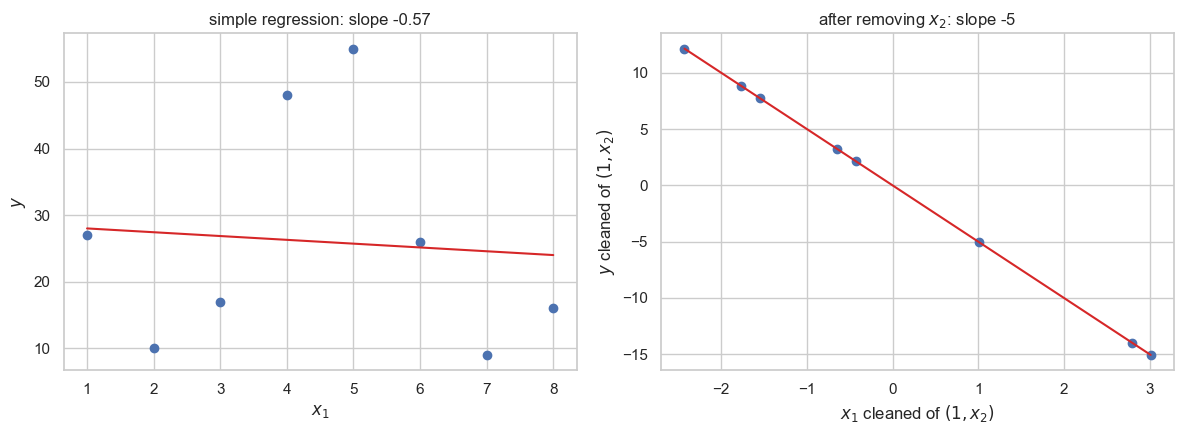

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(art['x1'], ya)
axes[0].plot(np.sort(art['x1']), np.polyval(np.polyfit(art['x1'], ya, 1), np.sort(art['x1'])), color='tab:red')
axes[0].set_xlabel('$x_1$'); axes[0].set_ylabel('$y$'); axes[0].set_title('simple regression: slope -0.57')
axes[1].scatter(x1_tilde, ya_tilde)
axes[1].plot(np.sort(x1_tilde), -5 * np.sort(x1_tilde), color='tab:red')
axes[1].set_xlabel('$x_1$ cleaned of $(1, x_2)$'); axes[1].set_ylabel('$y$ cleaned of $(1, x_2)$')
axes[1].set_title('after removing $x_2$: slope -5')
plt.tight_layout()
plt.show()

In Example 3.1 the points of the right panel lie exactly on a line through the origin with slope $-5$, because the fit is exact. Two remarks:
- If $\mathbf{x}_j$ is **orthogonal** to the other columns (after centring: uncorrelated with the other regressors), then $\mathbf{M}_{-j}\mathbf{x}_j$ is just the centred $\mathbf{x}_j$ and the multiple and simple regression slopes coincide. Correlated regressors are what makes them differ.
- If $\mathbf{x}_j$ is almost a linear combination of the others, $\mathbf{M}_{-j}\mathbf{x}_j$ is a short vector and the slope is estimated from very little information. This is multicollinearity, Remark 3.3, and Section 8 meets it from the numerical side.

## 7. When is the solution unique? Rank-deficient $\mathbf{X}$
Theorem 3.2: the normal equations **always have at least one solution**. Theorem 3.3: $\mathbf{X}^T\mathbf{X}$ is regular **if and only if** the columns of $\mathbf{X}$ are linearly independent, $h(\mathbf{X}) = m+1$. If they are dependent, there are infinitely many solutions $\widehat{\boldsymbol{\beta}}$, but by the board exercise of Section 4 they all give the same $\widehat{\mathbf{y}}$: the projection onto $\mathcal{M}(\mathbf{X})$ is unique, only its coordinates are not.

The classical way to get there by accident is the **dummy variable trap** (past indikátorových proměnných): an intercept and a dummy for *every* level of a factor. The three dummies of `origin` sum to the column of ones.

In [18]:
D = pd.get_dummies(cars['origin'], dtype=float)        # europe, japan, usa: all three levels
X_trap = np.column_stack([np.ones(n), cars['weight'], D])
names_trap = ['Intercept', 'weight'] + [f'origin={c}' for c in D.columns]

print('columns            :', X_trap.shape[1])
print('rank h(X)          :', np.linalg.matrix_rank(X_trap))
print('singular values    :', np.linalg.svd(X_trap, compute_uv=False))
print('eigenvalues of X^TX:', np.linalg.eigvalsh(X_trap.T @ X_trap))
print('np.linalg.cond(X)  :', f'{np.linalg.cond(X_trap):.2e}')

columns            : 5
rank h(X)          : 4
singular values    : [61299.0705    11.1064     8.5557     5.2638     0.    ]
eigenvalues of X^TX: [-5.6483e-15  2.7708e+01  7.3199e+01  1.2335e+02  3.7576e+09]
np.linalg.cond(X)  : 5.48e+18


In [19]:
# the vector v = (1, 0, -1, -1, -1) satisfies X v = 0: intercept minus the sum of the dummies
v = np.array([1., 0., -1., -1., -1.])
print('max |X v| =', np.abs(X_trap @ v).max())

fit_trap = sm.OLS(cars['mpg'], X_trap).fit()     # statsmodels default method='pinv'
b1 = fit_trap.params.to_numpy()
b2 = b1 + 10 * v                                 # another solution of the normal equations
display(pd.DataFrame({'pinv solution': b1, 'pinv + 10 v': b2}, index=names_trap))
print('normal equations residual for b2:', np.abs(X_trap.T @ X_trap @ b2 - X_trap.T @ cars['mpg']).max())
print('max |X b1 - X b2|               :', np.abs(X_trap @ b1 - X_trap @ b2).max())
print('df of residuals used by statsmodels:', fit_trap.df_resid, ' = n - rank =', n - np.linalg.matrix_rank(X_trap))

max |X v| = 0.0


,pinv solution,pinv + 10 v
Intercept,33.6237,43.6237
weight,-0.0070,-0.0070
origin=europe,11.0795,1.0795
origin=japan,12.4357,2.4357
origin=usa,10.1085,0.1085


normal equations residual for b2: 3.3527612686157227e-08
max |X b1 - X b2|               : 0.0
df of residuals used by statsmodels: 388.0  = n - rank = 388


- `statsmodels` does not complain. Its default method uses the pseudoinverse (Section 8.3), which picks the solution with the **smallest norm** $\|\widehat{\boldsymbol{\beta}}\|$, and it counts the degrees of freedom from the rank, not from the number of columns. The coefficients of the three dummies are meaningless on their own; only differences between them are identified.
- R behaves differently: `lm` uses a QR decomposition with column pivoting, detects the dependent column and reports its coefficient as `NA` ("not defined because of singularities").
- The formula interface avoids the trap automatically by dropping the reference level (Section 3). The trap appears when you build $\mathbf{X}$ by hand, e.g. with `pd.get_dummies` without `drop_first=True`.

Exact dependence is easy to detect. The real trouble is the case of Remark 3.3: columns that are *almost* dependent, $\mathbf{X}^T\mathbf{X}$ almost singular. The estimate exists and is unique, but it is sensitive to small changes of the data and to rounding errors. That is the subject of the next section, and multicollinearity will be treated in full at the end of the semester.

## 8. How is $\widehat{\boldsymbol{\beta}}$ computed?
Remark 3.1: the matrix $\mathbf{X}^T\mathbf{X}$ can be ill-conditioned, which affects the numerical accuracy of $\widehat{\boldsymbol{\beta}}$, and the Cholesky, QR and singular value decompositions are used in practice. The formula $(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$ is the right formula for theory and the wrong algorithm for computation. We implement four algorithms and compare them.

### 8.1 Normal equations: inverse, `solve`, Cholesky
$\mathbf{X}^T\mathbf{X}$ is symmetric and, for $h(\mathbf{X}) = m+1$, positive definite. It therefore has the **Cholesky decomposition** (Choleského rozklad) $\mathbf{X}^T\mathbf{X} = \mathbf{L}\mathbf{L}^T$ with a lower triangular $\mathbf{L}$, and the normal equations become two triangular systems,
$$\mathbf{L}\mathbf{z} = \mathbf{X}^T\mathbf{y}, \qquad \mathbf{L}^T\widehat{\boldsymbol{\beta}} = \mathbf{z},$$
each solved by simple substitution. Never compute an inverse to solve a system: `solve` or Cholesky is cheaper and at least as accurate.

In [20]:
def ols_inv(X, y):
    return np.linalg.inv(X.T @ X) @ (X.T @ y)


def ols_solve(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)


def ols_cholesky(X, y):
    L = np.linalg.cholesky(X.T @ X)                          # X^T X = L L^T
    z = sla.solve_triangular(L, X.T @ y, lower=True)         # L z = X^T y
    return sla.solve_triangular(L.T, z, lower=False)         # L^T beta = z

### 8.2 QR decomposition
Every $\mathbf{X}$ of full column rank can be written as $\mathbf{X} = \mathbf{Q}\mathbf{R}$, where $\mathbf{Q}$ ($n \times (m+1)$) has orthonormal columns, $\mathbf{Q}^T\mathbf{Q} = \mathbf{I}_{m+1}$, and $\mathbf{R}$ is upper triangular and regular. Substituting into the normal equations,
$$\mathbf{R}^T\mathbf{Q}^T\mathbf{Q}\mathbf{R}\boldsymbol{\beta} = \mathbf{R}^T\mathbf{Q}^T\mathbf{y} \;\Longrightarrow\; \mathbf{R}\widehat{\boldsymbol{\beta}} = \mathbf{Q}^T\mathbf{y}, \qquad \mathbf{H} = \mathbf{Q}\mathbf{Q}^T .$$
The product $\mathbf{X}^T\mathbf{X}$ is never formed. The columns of $\mathbf{Q}$ are an orthonormal basis of $\mathcal{M}(\mathbf{X})$, which is all a projection needs.

The textbook construction of $\mathbf{Q}$ is the **Gram–Schmidt orthogonalisation**: take the columns one by one and subtract from each its projection onto the previous ones. Each step is a small regression, the same "cleaning" as in Section 6.

In [21]:
def gram_schmidt(X):
    """Classical Gram-Schmidt: X = Q R with orthonormal Q and upper triangular R."""
    n, p = X.shape
    Q = np.zeros((n, p))
    R = np.zeros((p, p))
    for j in range(p):
        v = X[:, j].copy()
        for k in range(j):
            R[k, j] = Q[:, k] @ X[:, j]       # coefficient of the projection onto q_k
            v -= R[k, j] * Q[:, k]            # remove it
        R[j, j] = np.linalg.norm(v)
        Q[:, j] = v / R[j, j]
    return Q, R


def ols_qr(X, y):
    Q, R = np.linalg.qr(X)                    # Householder reflections (LAPACK), the stable way
    return sla.solve_triangular(R, Q.T @ y)


Q_gs, R_gs = gram_schmidt(X)
Q_np, R_np = np.linalg.qr(X)
print('Q^T Q = I            :', np.abs(Q_gs.T @ Q_gs - np.eye(p)).max())
print('Q R = X              :', np.abs(Q_gs @ R_gs - X).max() / np.abs(X).max())
print('same Q as numpy up to the sign of columns:', np.allclose(np.abs(Q_gs), np.abs(Q_np)))
print('H = Q Q^T            :', np.abs(Q_gs @ Q_gs.T - H).max())
print('beta from R beta = Q^T y:', sla.solve_triangular(R_gs, Q_gs.T @ y))

Q^T Q = I            : 6.121839146722152e-15
Q R = X              : 5.529515453385994e-18
same Q as numpy up to the sign of columns: True
H = Q Q^T            : 3.8510861166685117e-16
beta from R beta = Q^T y: [45.6402 -0.0058 -0.0473]


For the simple regression, $\mathbf{X} = (\mathbf{1}, \mathbf{x})$, the second Gram–Schmidt step gives $\mathbf{x} - \overline{x}\mathbf{1}$, the centred variable, with $r_{22} = \sqrt{S_{xx}}$. Solving $\mathbf{R}\widehat{\boldsymbol{\beta}} = \mathbf{Q}^T\mathbf{y}$ from the bottom row up gives $\widehat{\beta}_1 = S_{xy}/S_{xx}$ first and $\widehat{\beta}_0 = \overline{y} - \widehat{\beta}_1\overline{x}$ second: the formulas of Lecture 1 are back substitution in a QR decomposition.

Classical Gram–Schmidt as written above loses orthogonality for nearly dependent columns; libraries use Householder reflections (`np.linalg.qr`, R `qr`) or at least modified Gram–Schmidt.

### 8.3 Singular value decomposition (SVD)
Every $n \times (m+1)$ matrix can be written as (notation of the lecture notes, chapter on collinearity)
$$\mathbf{X} = \mathbf{P}\,\mathbf{S}\,\mathbf{Q}^T, \qquad \mathbf{S} = \mathrm{diag}(s_1, \dots, s_{m+1}),\ s_1 \ge \dots \ge s_{m+1} \ge 0,$$
where $\mathbf{P}$ ($n \times (m+1)$) and $\mathbf{Q}$ ($(m+1)\times(m+1)$) have orthonormal columns. (This $\mathbf{Q}$ is not the $\mathbf{Q}$ of the QR decomposition.) The **singular values** $s_j$ are the square roots of the eigenvalues of $\mathbf{X}^T\mathbf{X} = \mathbf{Q}\mathbf{S}^2\mathbf{Q}^T$. If all $s_j > 0$,

$$\widehat{\boldsymbol{\beta}} = \mathbf{Q}\mathbf{S}^{-1}\mathbf{P}^T\mathbf{y}, \qquad \mathbf{H} = \mathbf{P}\mathbf{P}^T, \qquad (\mathbf{X}^T\mathbf{X})^{-1} = \mathbf{Q}\mathbf{S}^{-2}\mathbf{Q}^T .$$

If some $s_j = 0$ (rank deficiency), replacing $1/s_j$ by $0$ for those $j$ gives the **Moore–Penrose pseudoinverse** $\mathbf{X}^+$ (pseudoinverze) and $\widehat{\boldsymbol{\beta}} = \mathbf{X}^+\mathbf{y}$ is the solution of the normal equations with the smallest norm. This is what `np.linalg.pinv`, `np.linalg.lstsq` and `statsmodels` (by default) do; it is the solution we saw in Section 7.

In [22]:
def ols_svd(X, y, rtol=1e-12):
    P, s, Qt = np.linalg.svd(X, full_matrices=False)          # X = P diag(s) Q^T
    s_inv = np.where(s > rtol * s[0], 1 / s, 0.0)             # pseudoinverse: drop zero singular values
    return Qt.T @ (s_inv * (P.T @ y))


P_, s_, Qt_ = np.linalg.svd(X, full_matrices=False)
print('singular values s_j        :', s_)
print('sqrt(eigenvalues of X^T X) :', np.sqrt(np.linalg.eigvalsh(X.T @ X))[::-1])
print('H = P P^T                  :', np.abs(P_ @ P_.T - H).max())
print('beta via SVD               :', ols_svd(X, y))

# the dummy variable trap of Section 7: the pseudoinverse solution
print('\ntrap, singular values      :', np.linalg.svd(X_trap, compute_uv=False))
print('trap, beta via SVD         :', ols_svd(X_trap, cars['mpg'].to_numpy()))
print('trap, statsmodels (pinv)   :', b1)

singular values s_j        : [61337.4509   387.9376     5.3457]
sqrt(eigenvalues of X^T X) : [61337.4509   387.9376     5.3457]
H = P P^T                  : 5.204170427930421e-16
beta via SVD               : [45.6402 -0.0058 -0.0473]

trap, singular values      : [61299.0705    11.1064     8.5557     5.2638     0.    ]
trap, beta via SVD         : [33.6237 -0.007  11.0795 12.4357 10.1085]
trap, statsmodels (pinv)   : [33.6237 -0.007  11.0795 12.4357 10.1085]


The SVD also shows where the variance of $\widehat{\boldsymbol{\beta}}$ comes from. Theorem 3.4 in the next lecture will show $\mathsf{Cov}\,\widehat{\boldsymbol{\beta}} = \sigma^2(\mathbf{X}^T\mathbf{X})^{-1}$; with the SVD
$$\mathsf{Var}\,\widehat{\beta}_j = \sigma^2 \sum_{k=1}^{m+1} \frac{q_{jk}^2}{s_k^2}.$$
A small singular value $s_k$ inflates the variance of every coefficient that has weight on the $k$-th direction $\mathbf{q}_k$. Almost dependent columns mean a small $s_{m+1}$, unstable estimates and wide confidence intervals. This formula is the starting point of the collinearity chapter and, in a later exercise, of ridge regression, which replaces $1/s_k$ by something smaller.

### 8.4 Condition number
The **condition number** (číslo podmíněnosti) of $\mathbf{X}$ is $\kappa(\mathbf{X}) = s_1/s_{m+1}$. As a rule of thumb, a computation with a matrix of condition number $\kappa$ can lose up to $\log_{10}\kappa$ significant digits; double precision has about 16. The normal equations work with $\mathbf{X}^T\mathbf{X}$, whose condition number is the **square**,
$$\kappa(\mathbf{X}^T\mathbf{X}) = \frac{s_1^2}{s_{m+1}^2} = \kappa(\mathbf{X})^2,$$
so they lose twice as many digits as QR or SVD, which work with $\mathbf{X}$ directly.

In [23]:
Z = X.copy()
Z[:, 1:] = (Z[:, 1:] - Z[:, 1:].mean(axis=0)) / Z[:, 1:].std(axis=0)     # centred and scaled regressors
for lab, A in [('mpg ~ weight + horsepower, raw', X), ('the same, standardized', Z)]:
    print(f'{lab:35s} kappa(X) = {np.linalg.cond(A):10.3e}   kappa(X^T X) = {np.linalg.cond(A.T @ A):10.3e}')

mpg ~ weight + horsepower, raw      kappa(X) =  1.147e+04   kappa(X^T X) =  1.317e+08
the same, standardized              kappa(X) =  3.710e+00   kappa(X^T X) =  1.376e+01


Part of the large condition number of the raw matrix is only due to **units**: the weight column is in thousands, the intercept column is ones. Scaling the columns does not change $\widehat{\mathbf{y}}$ (Section 5) but helps the numerics. Centring removes the near-dependence between a variable with large values and the intercept column. A condition number around $10^4$ is harmless in double precision; the next two examples are not.

### 8.5 Longley data: comparison with certified values
The **Longley data** (1967) are 16 yearly observations of the US economy, 1947–1962: total employment `TOTEMP` regressed on six strongly correlated macroeconomic variables (GNP deflator, GNP, unemployment, armed forces, population, year). Longley showed that the regression programs of the 1960s returned numbers with not a single correct digit. The US National Institute of Standards and Technology (NIST) publishes **certified values** of the estimates, computed in 500-digit arithmetic, as a test of statistical software (Statistical Reference Datasets, StRD).

Accuracy is measured by the **log relative error** $\mathrm{LRE} = -\log_{10}\big(|\widehat{\beta}_j - \beta_j^{\mathrm{cert}}|/|\beta_j^{\mathrm{cert}}|\big)$, roughly the number of correct significant digits.

In [24]:
longley = sm.datasets.longley.load_pandas()
XL = sm.add_constant(longley.exog).to_numpy(dtype=float)
yL = longley.endog.to_numpy(dtype=float)
names_L = ['const'] + list(longley.exog.columns)

# NIST StRD certified values, https://www.itl.nist.gov/div898/strd/lls/data/Longley.shtml
beta_cert = np.array([-3482258.63459582, 15.0618722713733, -0.358191792925910E-01, -2.02022980381683,
                      -1.03322686717359, -0.511041056535807E-01, 1829.15146461355])
display(pd.DataFrame(XL, columns=names_L).describe().T[['mean', 'std', 'min', 'max']])
print(f'kappa(X) = {np.linalg.cond(XL):.2e},  kappa(X^T X) = {np.linalg.cond(XL.T @ XL):.2e}')

,mean,std,min,max
const,1.0000,0.0000,1.0,1.0
GNPDEFL,101.6813,10.7916,83.0,116.9
GNP,387698.4375,99394.9378,234289.0,554894.0
UNEMP,3193.3125,934.4642,1870.0,4806.0
ARMED,2606.6875,695.9196,1456.0,3594.0
POP,117424.0000,6956.1016,107608.0,130081.0
YEAR,1954.5000,4.7610,1947.0,1962.0


kappa(X) = 4.86e+09,  kappa(X^T X) = 2.38e+19


In [25]:
def lre(b, cert=beta_cert):
    rel = np.abs(b - cert) / np.abs(cert)
    return np.clip(-np.log10(np.maximum(rel, 1e-17)), 0, 16)


methods = {'inverse': ols_inv, 'solve (normal eq.)': ols_solve, 'Cholesky': ols_cholesky,
           'QR': ols_qr, 'SVD': ols_svd,
           'numpy lstsq': lambda X, y: np.linalg.lstsq(X, y, rcond=None)[0],
           'statsmodels pinv': lambda X, y: sm.OLS(y, X).fit().params,
           'statsmodels qr': lambda X, y: sm.OLS(y, X).fit(method='qr').params}

table = pd.DataFrame({k: lre(f(XL, yL)) for k, f in methods.items()}, index=names_L).T
table['min LRE'] = table.min(axis=1)
table.round(1)

,const,GNPDEFL,GNP,UNEMP,ARMED,POP,YEAR,min LRE
inverse,8.2,7.4,7.7,8.3,8.6,7.4,8.2,7.4
solve (normal eq.),8.2,7.5,7.7,8.3,8.6,7.4,8.2,7.4
Cholesky,8.0,7.5,7.6,8.1,8.4,7.2,8.0,7.2
QR,12.2,10.9,11.8,12.5,13.1,11.7,12.2,10.9
SVD,12.2,11.0,11.9,12.5,13.2,11.7,12.2,11.0
numpy lstsq,12.2,11.0,11.8,12.5,12.9,11.9,12.2,11.0
statsmodels pinv,12.2,11.0,11.9,12.5,13.2,11.8,12.3,11.0
statsmodels qr,12.2,10.9,11.8,12.5,13.1,11.7,12.2,10.9


In double precision every method gives at least 7 correct digits, so for this data set the results are all usable. But the normal equations lose about four digits compared with QR and SVD, in line with $\log_{10}\kappa(\mathbf{X}^T\mathbf{X}) \approx 19$ versus $\log_{10}\kappa(\mathbf{X}) \approx 10$.

To see what this means with fewer digits to spare, repeat the computation in **single precision** (`float32`, about 7 significant digits), a stand-in for the machines of 1967 and for GPUs today:

In [26]:
XL32, yL32 = XL.astype(np.float32), yL.astype(np.float32)
single = {'inverse': ols_inv, 'Cholesky': ols_cholesky, 'QR': ols_qr, 'SVD': ols_svd}
rows = {}
for k, f in single.items():
    try:
        rows[k] = lre(f(XL32, yL32).astype(float))
    except np.linalg.LinAlgError as err:
        rows[k] = np.full(len(names_L), np.nan)
        print(f'{k}: failed ({err})')
table32 = pd.DataFrame(rows, index=names_L).T
table32['min LRE'] = table32.min(axis=1)
table32.round(1)

Cholesky: failed (Matrix is not positive definite)


,const,GNPDEFL,GNP,UNEMP,ARMED,POP,YEAR,min LRE
inverse,0.0,0.0,0.0,0.0,0.3,0.0,0.0,0.0
Cholesky,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
QR,5.6,4.4,5.2,5.8,6.3,4.7,5.6,4.4
SVD,5.3,4.9,5.0,5.4,5.5,4.8,5.3,4.8


With 7 digits available and $\kappa(\mathbf{X}^T\mathbf{X}) \approx 10^{19}$, the normal equations have nothing left: not one correct digit (or the Cholesky decomposition fails because $\mathbf{X}^T\mathbf{X}$ is not numerically positive definite). QR and SVD still give several correct digits. This is exactly Longley's 1967 finding.

The cure from Section 8.4 works here too: standardizing the regressors brings $\kappa(\mathbf{X})$ from about $5\cdot 10^9$ to about $10^2$. The remaining condition number reflects real collinearity of the economic variables, which no rescaling removes; we return to these data in the chapter on collinearity.

In [27]:
ZL = XL.copy()
ZL[:, 1:] = (ZL[:, 1:] - ZL[:, 1:].mean(axis=0)) / ZL[:, 1:].std(axis=0)
print(f'Longley standardized: kappa(X) = {np.linalg.cond(ZL):.1f}')
print('correlations of the regressors:')
longley.exog.corr().round(3)

Longley standardized: kappa(X) = 110.5
correlations of the regressors:


,GNPDEFL,GNP,UNEMP,ARMED,POP,YEAR
GNPDEFL,1.000,0.992,0.621,0.465,0.979,0.991
GNP,0.992,1.000,0.604,0.446,0.991,0.995
UNEMP,0.621,0.604,1.000,-0.177,0.687,0.668
ARMED,0.465,0.446,-0.177,1.000,0.364,0.417
POP,0.979,0.991,0.687,0.364,1.000,0.994
YEAR,0.991,0.995,0.668,0.417,0.994,1.000


### 8.6 Polynomial in the calendar year
A trap that is easy to fall into: a polynomial trend in the year, $y = \beta_0 + \beta_1 t + \beta_2 t^2 + \beta_3 t^3$, with $t = 1990, \dots, 2020$. The columns $t^k$ are of the order $10^{3k}$ and almost proportional to each other.

In [28]:
t = np.arange(1990, 2021).astype(float)
y_t = np.sin((t - 1990) / 5) + rng.normal(0, 0.1, t.size)
rows = []
for deg in [2, 3, 5]:
    X_raw = np.vander(t, deg + 1, increasing=True)                 # 1, t, t^2, ...
    X_std = np.vander((t - t.mean()) / t.std(), deg + 1, increasing=True)
    fit_ref = X_std @ ols_qr(X_std, y_t)
    rows.append({'degree': deg,
                 'kappa(X) raw': np.linalg.cond(X_raw), 'kappa(X) standardized': np.linalg.cond(X_std),
                 'max|fit error| inverse, raw': np.abs(X_raw @ ols_inv(X_raw, y_t) - fit_ref).max(),
                 'max|fit error| QR, raw': np.abs(X_raw @ ols_qr(X_raw, y_t) - fit_ref).max(),
                 'max|fit error| inverse, standardized': np.abs(X_std @ ols_inv(X_std, y_t) - fit_ref).max()})
pd.DataFrame(rows).set_index('degree').map(lambda v: f'{v:.1e}')

,kappa(X) raw,kappa(X) standardized,"max|fit error| inverse, raw","max|fit error| QR, raw","max|fit error| inverse, standardized"
degree,,,,,
2,2.3e+11,2.8e+00,1.9e-07,1.5e-12,1.7e-16
3,1.2e+17,6.0e+00,2.0e-01,5.7e-09,1.4e-15
5,2.9e+28,3.8e+01,1.6e-01,2.0e-04,2.7e-14


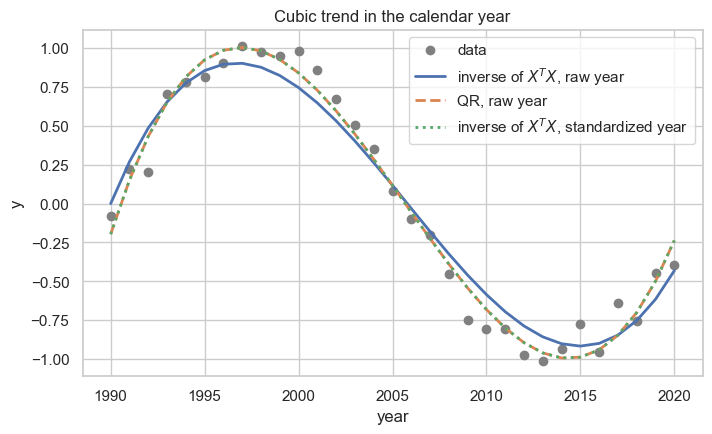

In [29]:
deg = 3
X_raw = np.vander(t, deg + 1, increasing=True)
X_std = np.vander((t - t.mean()) / t.std(), deg + 1, increasing=True)
plt.figure(figsize=(8, 4.5))
plt.scatter(t, y_t, color='gray', label='data')
plt.plot(t, X_raw @ ols_inv(X_raw, y_t), label='inverse of $X^TX$, raw year', lw=2)
plt.plot(t, X_raw @ ols_qr(X_raw, y_t), label='QR, raw year', lw=2, ls='--')
plt.plot(t, X_std @ ols_inv(X_std, y_t), label='inverse of $X^TX$, standardized year', lw=2, ls=':')
plt.xlabel('year'); plt.ylabel('y'); plt.legend(); plt.title('Cubic trend in the calendar year')
plt.show()

All three curves estimate the same model, $\widehat{\mathbf{y}}$ is the same projection. With the raw year the normal equations return a visibly wrong curve already for a cubic. QR on the same raw matrix is still accurate for a cubic and loses several digits only for higher degrees (degree 5 in the table). Standardizing the year fixes everything. Practical rule: **centre and scale variables before building polynomials and interactions**. R's `poly()` goes further and builds orthogonal polynomial columns.

### 8.7 What the software does, and how fast
| Software | Default algorithm | Rank deficiency |
|---|---|---|
| `statsmodels` `OLS.fit()` | pseudoinverse via SVD (`method='pinv'`); `method='qr'` available | minimum-norm solution, df from the rank |
| `numpy.linalg.lstsq`, `scipy.linalg.lstsq` | SVD (LAPACK `gelsd`) | minimum-norm solution, returns the rank |
| `scikit-learn` `LinearRegression` | `scipy.linalg.lstsq` | minimum-norm solution |
| R `lm` | QR with column pivoting (Householder) | `NA` for dependent columns |

Speed matters for large data: the normal equations need about $n p^2$ operations to form $\mathbf{X}^T\mathbf{X}$, QR about $2np^2$, SVD a few times more. A rough timing:

In [30]:
n_big, p_big = 20000, 100
X_big = np.column_stack([np.ones(n_big), rng.normal(size=(n_big, p_big - 1))])
y_big = X_big @ rng.normal(size=p_big) + rng.normal(size=n_big)

timing = {}
for k in ['inverse', 'Cholesky', 'QR', 'SVD', 'numpy lstsq']:
    f = methods[k]
    start = time.perf_counter()
    for _ in range(3):
        b = f(X_big, y_big)
    timing[k] = (time.perf_counter() - start) / 3 * 1000
pd.Series(timing, name='time [ms]').round(1)

inverse         28.6
Cholesky         9.1
QR             160.6
SVD            157.3
numpy lstsq     69.1
Name: time [ms], dtype: float64

For well-conditioned data the fast normal equations are fine and are used in big-data software; for anything else the default of good software is QR or SVD. You will rarely implement these algorithms yourself, but you should recognise the symptoms: absurd coefficients, a warning about a large condition number in `summary()`, and different results from different programs.

## 9. Individual work: advertising data with all three media
The `Advert.csv` data from Exercise 03: `sales` (thousands of units) and the advertising budget for `TV`, `radio` and `newspaper` (thousands of dollars) in 200 markets. In Exercise 03 we used simple regressions only; now take all three media together. Write a short conclusion after each step.

1. Build the model matrix $\mathbf{X}$ for `sales ~ TV + radio + newspaper` by hand (numpy) and with `dmatrices`, and check that they agree.
2. Compute $\widehat{\boldsymbol{\beta}}$ with your own QR solution and your own SVD solution, and compare with `statsmodels`. Compare also with the three simple regression slopes from Exercise 03. Which coefficient changed the most?
3. Verify $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$, $\mathrm{tr}(\mathbf{H}) = m+1$ and $R^2 = \mathrm{corr}^2(\mathbf{y}, \widehat{\mathbf{y}})$.
4. Use the Frisch–Waugh–Lovell theorem to explain the change of the `newspaper` coefficient: regress `newspaper` on the other media, look at the correlation matrix of the three budgets, and draw the plot of the cleaned `sales` against the cleaned `newspaper`.
5. Find the five markets with the largest leverage $h_{ii}$. What is special about their budgets?
6. Compute $\kappa(\mathbf{X})$ for the raw and the standardized regressors. Is there a numerical problem here?
7. Add the column `total = TV + radio + newspaper` to $\mathbf{X}$. What is the rank? What do `statsmodels` and your QR solution do? Are the fitted values still the same?

In [31]:
url_adv = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/Advert.csv'
advert = pd.read_csv(url_adv, index_col=0)
advert.head()

,TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [32]:
# your solution


## 10. What to remember
- The model is linear in $\boldsymbol{\beta}$; the columns of $\mathbf{X}$ can be dummies, interactions or polynomials. A factor with $k$ levels gives $k-1$ dummies next to an intercept.
- Normal equations $\Leftrightarrow$ $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$: the residuals are orthogonal to all columns. $\widehat{\mathbf{y}} = \mathbf{H}\mathbf{y}$ is the orthogonal projection onto $\mathcal{M}(\mathbf{X})$; Pythagoras gives $\mathrm{SST} = \mathrm{SSR} + \mathrm{SSE}$ and $R^2 = \mathrm{corr}^2(\mathbf{y}, \widehat{\mathbf{y}})$.
- $\mathbf{H}$ and $\mathbf{M} = \mathbf{I}_n - \mathbf{H}$ are symmetric and idempotent, $\mathrm{tr}\,\mathbf{H} = m+1$, $\mathrm{tr}\,\mathbf{M} = n-m-1$; $\mathbf{H}$ depends only on the column space, so reparametrisation changes $\widehat{\boldsymbol{\beta}}$ but not $\widehat{\mathbf{y}}$. $h_{ii}$ is the leverage, $1 - h_{ii}$ appears in the studentized residuals.
- $\widehat{\beta}_j$ is the slope of $y$ on $x_j$ after removing the other regressors from both (Frisch–Waugh–Lovell); it equals the simple regression slope only for orthogonal regressors.
- Dependent columns: infinitely many $\widehat{\boldsymbol{\beta}}$, one $\widehat{\mathbf{y}}$; `statsmodels` returns the minimum-norm solution, R `NA`.
- Compute with QR or SVD, not with $(\mathbf{X}^T\mathbf{X})^{-1}$: $\kappa(\mathbf{X}^T\mathbf{X}) = \kappa(\mathbf{X})^2$. Centre and scale regressors, especially before polynomials. Small singular values mean large variances of the estimates.